# BÀI THỰC HÀNH 3: MẠNG NEURAL HỒI QUY CHO BÀI TOÁN PHÂN LOẠI VĂN BẢN VÀ GÁN NHÃN CHUỖI

Bộ dữ liệu sử dụng: [UIT-VSFC](https://drive.google.com/drive/folders/1rdcXNGt_3-QUvV8EtSvVsLMVeHmk6Yqk?usp=drive_link) và [PhoNERT](https://github.com/VinAIResearch/PhoNER_COVID19).

In [2]:
import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch :", torch.__version__)
print("device :", device)

import copy, json, random, time, urllib.request
from collections import Counter
from pathlib import Path

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from seqeval.metrics import classification_report as entity_report
from seqeval.metrics import f1_score as entity_f1
from seqeval.metrics.sequence_labeling import get_entities
from seqeval.scheme import IOB2

def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

torch : 2.11.0+cu130
device : cuda


In [3]:
SEED = 42
NUM_LAYERS = 5
HIDDEN_SIZE = 256
EMB_DIM = 300
DROPOUT = 0.3
LR = 1e-3
BATCH_SIZE = 32
EPOCHS = 10
CLIP = 1.0
MIN_FREQ = 2
 
PAD_ID = 0
UNK_ID = 1
IGNORE_ID = -100
 
LABELS = ["negative", "neutral", "positive"]
LABEL_TO_ID = {label: i for i, label in enumerate(LABELS)}
 
DATA_DIR = Path("data")

In [4]:
VSFC_IDS = {
    "train": "1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX",
    "dev": "1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe",
    "test": "1g4imdabNbswIu91K6zKFGalkjDBBqaQq",
}
PHONER_URL = ("https://raw.githubusercontent.com/VinAIResearch/PhoNER_COVID19/"
              "main/data/syllable/{}_syllable.json")

(DATA_DIR / "uit-vsfc").mkdir(parents=True, exist_ok=True)
(DATA_DIR / "phoner").mkdir(parents=True, exist_ok=True)

for split in ["train", "dev", "test"]:
    vsfc_path = DATA_DIR / "uit-vsfc" / f"UIT-VSFC-{split}.json"
    if not vsfc_path.exists():
        gdown.download(id=VSFC_IDS[split], output=str(vsfc_path), quiet=False)
    ner_path = DATA_DIR / "phoner" / f"{split}_syllable.json"
    if not ner_path.exists():
        urllib.request.urlretrieve(PHONER_URL.format(split), ner_path)
print("Đã tải xong dữ liệu.")

Downloading...
From: https://drive.google.com/uc?id=1eJdEStCQBf3GtbOIQfIR2iS-Wb3nlfJX
To: /kaggle/working/data/uit-vsfc/UIT-VSFC-train.json
100%|██████████| 2.02M/2.02M [00:00<00:00, 157MB/s]
Downloading...
From: https://drive.google.com/uc?id=1UWbzHFeUPu4AuofOEy0Fo0SFotVZHzUe
To: /kaggle/working/data/uit-vsfc/UIT-VSFC-dev.json
100%|██████████| 274k/274k [00:00<00:00, 77.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1g4imdabNbswIu91K6zKFGalkjDBBqaQq
To: /kaggle/working/data/uit-vsfc/UIT-VSFC-test.json
100%|██████████| 559k/559k [00:00<00:00, 108MB/s]


Đã tải xong dữ liệu.


In [5]:
vsfc, ner = {}, {}
for split in ["train", "dev", "test"]:
    text = (DATA_DIR / "uit-vsfc" / f"UIT-VSFC-{split}.json").read_text(encoding="utf-8-sig")
    vsfc[split] = json.loads(text)
    
    lines = (DATA_DIR / "phoner" / f"{split}_syllable.json").read_text(encoding="utf-8-sig").splitlines()
    ner[split] = [json.loads(l) for l in lines if l.strip()]

print("UIT-VSFC:", {split: len(rows) for split, rows in vsfc.items()})
print("PhoNER  :", {split: len(rows) for split, rows in ner.items()})

tag_set = set()
for row in ner["train"]:
    tag_set.update(row["tags"])
TAGS = sorted(tag_set)
TAG_TO_ID = {tag: i for i, tag in enumerate(TAGS)}
print("Số nhãn BIO:", len(TAGS))

UIT-VSFC: {'train': 11426, 'dev': 1583, 'test': 3166}
PhoNER  : {'train': 5027, 'dev': 2000, 'test': 3000}
Số nhãn BIO: 21


In [6]:
def tokenize(text):
    return text.lower().split()

def build_vocab(token_lists, min_freq=MIN_FREQ):
    counter = Counter()
    for tokens in token_lists:
        counter.update(tokens)

    vocab = {"<pad>": PAD_ID, "<unk>": UNK_ID}
    for word in sorted(counter):
        if counter[word] >= min_freq:
            vocab[word] = len(vocab)
    return vocab

def encode(tokens, vocab):
    ids = [vocab.get(token, UNK_ID) for token in tokens]
    if len(ids) == 0:
        ids = [UNK_ID]
    return ids

def ids_to_tags(id_lists):
    tag_lists = []
    for ids in id_lists:
        tag_lists.append([TAGS[i] for i in ids])
    return tag_lists

def collate_cls(batch):
    ids_list = [torch.tensor(ids) for ids, _ in batch]
    lengths = torch.tensor([len(ids) for ids in ids_list])
    ids_padded = pad_sequence(ids_list, batch_first=True, padding_value=PAD_ID)
    labels = torch.tensor([label for _, label in batch])
    return ids_padded, lengths, labels

def collate_ner(batch):
    ids_list = [torch.tensor(ids) for ids, _ in batch]
    tags_list = [torch.tensor(tag_ids) for _, tag_ids in batch]
    lengths = torch.tensor([len(ids) for ids in ids_list])
    ids_padded = pad_sequence(ids_list, batch_first=True, padding_value=PAD_ID)
    tags_padded = pad_sequence(tags_list, batch_first=True, padding_value=IGNORE_ID)
    return ids_padded, lengths, tags_padded

def make_loader(rows, collate_fn, shuffle):
    return DataLoader(rows, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collate_fn,
                      generator=torch.Generator().manual_seed(SEED))


In [7]:
def compute_f1(y_true, y_pred, task):
    if task == "cls":
        return f1_score(y_true, y_pred, average="macro", zero_division=0)
    return entity_f1(ids_to_tags(y_true), ids_to_tags(y_pred),
                     mode="strict", scheme=IOB2, zero_division=0)


def evaluate(model, loader, task):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_ID)
    total_loss, total_count = 0.0, 0
    y_true, y_pred = [], []

    with torch.no_grad():
        for ids, lengths, labels in loader:
            ids, labels = ids.to(device), labels.to(device)
            logits = model(ids, lengths)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))
            
            count = (labels != IGNORE_ID).sum().item()
            total_loss += loss.item() * count
            total_count += count

            preds = logits.argmax(dim=-1)
            if task == "cls":
                y_true += labels.tolist()
                y_pred += preds.tolist()
            else:
                for i in range(len(lengths)):
                    n = lengths[i].item()
                    y_true.append(labels[i, :n].tolist())
                    y_pred.append(preds[i, :n].tolist())

    return total_loss / total_count, compute_f1(y_true, y_pred, task), y_true, y_pred


def train_model(model, train_loader, dev_loader, task):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.CrossEntropyLoss(ignore_index=IGNORE_ID)

    history = {"train_loss": [], "dev_loss": [], "dev_f1": [], "seconds": []}
    best_f1, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, EPOCHS + 1):
        model.train()
        start = time.perf_counter()
        total_loss, total_count = 0.0, 0
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(device), labels.to(device)
            logits = model(ids, lengths)
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), labels.reshape(-1))

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            optimizer.step()

            count = (labels != IGNORE_ID).sum().item()
            total_loss += loss.item() * count
            total_count += count
        seconds = time.perf_counter() - start
        train_loss = total_loss / total_count

        
        dev_loss, dev_f1, _, _ = evaluate(model, dev_loader, task)

        history["train_loss"].append(train_loss)
        history["dev_loss"].append(dev_loss)
        history["dev_f1"].append(dev_f1)
        history["seconds"].append(seconds)
        print(f"Epoch {epoch:2d} | train loss {train_loss:.4f} | "
              f"dev loss {dev_loss:.4f} F1 {dev_f1:.4f} | thời gian {seconds:.1f}s")

        
        if dev_f1 > best_f1:
            best_f1, best_epoch = dev_f1, epoch
            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    print(f"Epoch tốt nhất theo dev: {best_epoch} (F1 dev = {best_f1:.4f})")
    return history, best_epoch


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(10, 3.5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], marker="o", label="train")
    plt.plot(epochs, history["dev_loss"], marker="o", label="dev")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["dev_f1"], marker="o")
    plt.title(f"{title} - F1 (dev)")
    plt.xlabel("Epoch")

    plt.tight_layout()
    plt.show()

### Bài 1: Xây dựng mạng LSTM gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [8]:
train_tokens = [tokenize(row["sentence"]) for row in vsfc["train"]]
vocab = build_vocab(train_tokens)
print("Kích thước từ điển:", len(vocab))

cls_data = {}
for split in ["train", "dev", "test"]:
    cls_data[split] = []
    for row in vsfc[split]:
        ids = encode(tokenize(row["sentence"]), vocab)
        label = LABEL_TO_ID[row["sentiment"]]
        cls_data[split].append((ids, label))

cls_dev_loader = make_loader(cls_data["dev"], collate_cls, shuffle=False)
cls_test_loader = make_loader(cls_data["test"], collate_cls, shuffle=False)

Kích thước từ điển: 1535


In [9]:
class SentimentRNN(nn.Module):
    # Embedding - LSTM/GRU - Linear.

    def __init__(self, vocab_size, rnn_type, num_layers):
        super().__init__()
        self.rnn_type = rnn_type
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD_ID)

        rnn_dropout = DROPOUT if num_layers > 1 else 0.0
        if rnn_type == "LSTM":
            self.rnn = nn.LSTM(EMB_DIM, HIDDEN_SIZE, num_layers, batch_first=True, dropout=rnn_dropout)
        else:
            self.rnn = nn.GRU(EMB_DIM, HIDDEN_SIZE, num_layers, batch_first=True, dropout=rnn_dropout)

        self.dropout = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(HIDDEN_SIZE, len(LABELS))

    def forward(self, ids, lengths):
        emb = self.embedding(ids)
        
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        if self.rnn_type == "LSTM":
            _, (h_n, c_n) = self.rnn(packed)
        else:
            _, h_n = self.rnn(packed)
        last_hidden = h_n[-1]
        return self.fc(self.dropout(last_hidden))


def run_classification(rnn_type, num_layers):
    print(f">{rnn_type} {num_layers} lớp")
    seed_all(SEED)
    model = SentimentRNN(len(vocab), rnn_type, num_layers).to(device)
    params = sum(p.numel() for p in model.parameters())
    print(f"Số tham số: {params:,}")

    train_loader = make_loader(cls_data["train"], collate_cls, shuffle=True)
    history, best_epoch = train_model(model, train_loader, cls_dev_loader, "cls")

    _, test_f1, test_true, test_pred = evaluate(model, cls_test_loader, "cls")
    return {"model": model, "params": params, "history": history, "best_epoch": best_epoch,
            "test_f1": test_f1, "test_true": test_true, "test_pred": test_pred}

In [10]:
res_lstm = run_classification("LSTM", NUM_LAYERS)

>LSTM 5 lớp
Số tham số: 3,138,007
Epoch  1 | train loss 0.4237 | dev loss 0.3584 F1 0.6905 | thời gian 9.3s
Epoch  2 | train loss 0.2725 | dev loss 0.2788 F1 0.7331 | thời gian 5.3s
Epoch  3 | train loss 0.2307 | dev loss 0.2684 F1 0.7388 | thời gian 5.3s
Epoch  4 | train loss 0.1915 | dev loss 0.2639 F1 0.7789 | thời gian 5.2s
Epoch  5 | train loss 0.1672 | dev loss 0.2785 F1 0.7729 | thời gian 5.3s
Epoch  6 | train loss 0.1390 | dev loss 0.2658 F1 0.7961 | thời gian 5.2s
Epoch  7 | train loss 0.1199 | dev loss 0.3283 F1 0.7747 | thời gian 5.3s
Epoch  8 | train loss 0.1013 | dev loss 0.3089 F1 0.8036 | thời gian 5.2s
Epoch  9 | train loss 0.0909 | dev loss 0.3669 F1 0.7809 | thời gian 5.3s
Epoch 10 | train loss 0.0805 | dev loss 0.3567 F1 0.7918 | thời gian 5.3s
Epoch tốt nhất theo dev: 8 (F1 dev = 0.8036)


              precision    recall  f1-score   support

    negative     0.9010    0.9297    0.9151      1409
     neutral     0.5678    0.4012    0.4702       167
    positive     0.9235    0.9258    0.9246      1590

    accuracy                         0.8999      3166
   macro avg     0.7974    0.7522    0.7700      3166
weighted avg     0.8947    0.8999    0.8964      3166



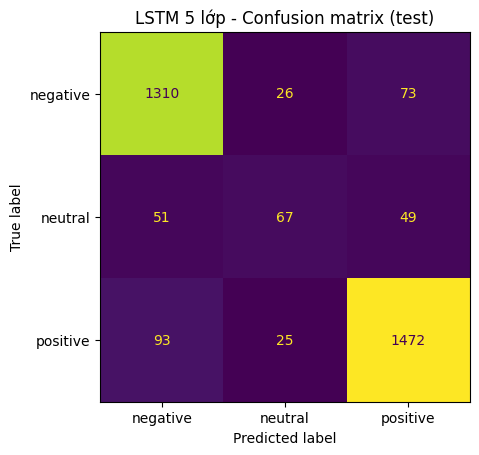

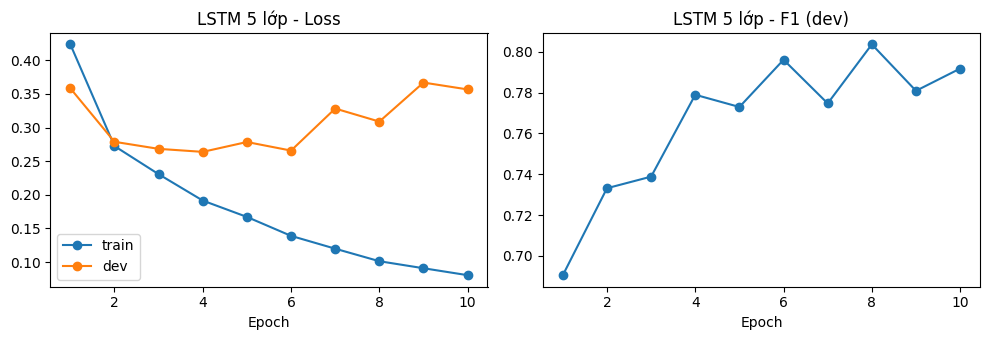

In [11]:
print(classification_report(res_lstm["test_true"], res_lstm["test_pred"],
                            target_names=LABELS, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(res_lstm["test_true"], res_lstm["test_pred"],
                                        labels=[0, 1, 2], display_labels=LABELS, colorbar=False)
plt.title("LSTM 5 lớp - Confusion matrix (test)")
plt.show()

plot_history(res_lstm["history"], "LSTM 5 lớp")

- Epoch 8 cho dev macro-F1 cao nhất (0.8036), trên test đạt macro-F1 0.77 
- F1 của negative là 0.9151 và của positive là 0.9246, còn neutral chỉ 0.4702. Nguyên nhân có thể do neutral chỉ chiếm khoảng 4% trong UIT-VSFC, và phân biệt câu neutral tương đối khó vì ranh giới không rõ ràng
- Dev loss thấp nhất ở epoch 4 (0.2639) rồi tăng dần, trong khi dev F1 vẫn dao động quanh 0.77-0.8, dấu hiệu overfit

In [12]:
_, _, dev_true, dev_pred = evaluate(res_lstm["model"], cls_dev_loader, "cls")
wrong = []
for i in range(len(dev_true)):
    if dev_true[i] != dev_pred[i]:
        wrong.append(i)

print(f"Số câu sai trên dev: {len(wrong)}/{len(dev_true)}")
for i in wrong[:5]:
    print(f"_ nhãn thật: {LABELS[dev_true[i]]} | dự đoán: {LABELS[dev_pred[i]]}")
    print(f"  {vsfc['dev'][i]['sentence']}")

Số câu sai trên dev: 121/1583
_ nhãn thật: neutral | dự đoán: negative
  em không có bất cứ một lời phê bình nào .
_ nhãn thật: neutral | dự đoán: positive
  thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề .
_ nhãn thật: positive | dự đoán: neutral
  cô dạy đều , bao giờ cũng đến sớm và đúng giờ .
_ nhãn thật: negative | dự đoán: neutral
  cô rất nghiêm .
_ nhãn thật: positive | dự đoán: negative
  ngoài ra cung cấp một vài thông tin bổ sung về việc học công nghệ thông tin hiệu quả hơn .


1."em không có bất cứ một lời phê bình nào": nguyên nhân có thể do từ không và phê bình, mô hình không hiểu là phủ định

2."thầy cho tự tìm hiểu , và tự tìm hiểu khác với hiểu được vấn đề": cần suy luận để hiểu ý nghĩa, khó phân biệt rõ ý kiến dạng này

3."cô dạy đều , bao giờ cũng đến sớm và đúng giờ": mô tả hành vi, không thể hiện rõ trạng thái tích cực

4."cô rất nghiêm": câu ngắn, từ nghiêm chưa chắc đã là chê hay khen

Nhận xét: các câu dự đoán sai thường do câu mơ hồ, không rõ sắc thái

### Bài 2: Xây dựng mạng GRU gồm 5 lớp với hidden size là 256 cho bài toán phân loại văn bản. Huấn luyện mô hình này trên bộ dữ liệu UIT-VSFC (Vietnamese Student Feedback Corpus) sử dụng Adam làm phương thức tối ưu tham số và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [13]:
res_gru = run_classification("GRU", NUM_LAYERS)

>GRU 5 lớp
Số tham số: 2,468,823
Epoch  1 | train loss 0.3845 | dev loss 0.2984 F1 0.7179 | thời gian 5.0s
Epoch  2 | train loss 0.2618 | dev loss 0.2998 F1 0.7640 | thời gian 5.0s
Epoch  3 | train loss 0.2169 | dev loss 0.2409 F1 0.7913 | thời gian 4.9s
Epoch  4 | train loss 0.1831 | dev loss 0.2586 F1 0.7991 | thời gian 4.9s
Epoch  5 | train loss 0.1534 | dev loss 0.3192 F1 0.7732 | thời gian 4.9s
Epoch  6 | train loss 0.1282 | dev loss 0.3133 F1 0.7704 | thời gian 4.9s
Epoch  7 | train loss 0.1117 | dev loss 0.3405 F1 0.7790 | thời gian 4.9s
Epoch  8 | train loss 0.0963 | dev loss 0.3327 F1 0.8014 | thời gian 4.9s
Epoch  9 | train loss 0.0783 | dev loss 0.3717 F1 0.7829 | thời gian 5.0s
Epoch 10 | train loss 0.0693 | dev loss 0.3774 F1 0.7809 | thời gian 5.0s
Epoch tốt nhất theo dev: 8 (F1 dev = 0.8014)


              precision    recall  f1-score   support

    negative     0.9109    0.9354    0.9230      1409
     neutral     0.4672    0.3832    0.4211       167
    positive     0.9317    0.9270    0.9294      1590

    accuracy                         0.9021      3166
   macro avg     0.7699    0.7486    0.7578      3166
weighted avg     0.8979    0.9021    0.8997      3166



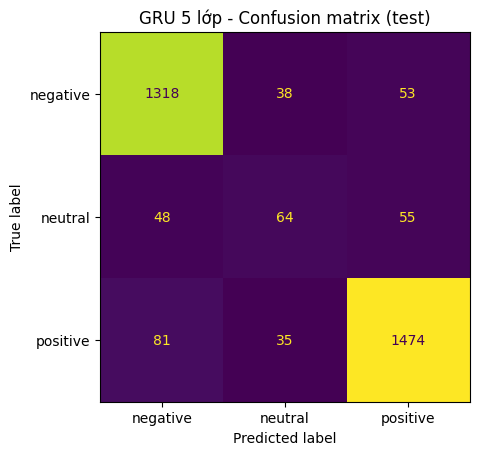

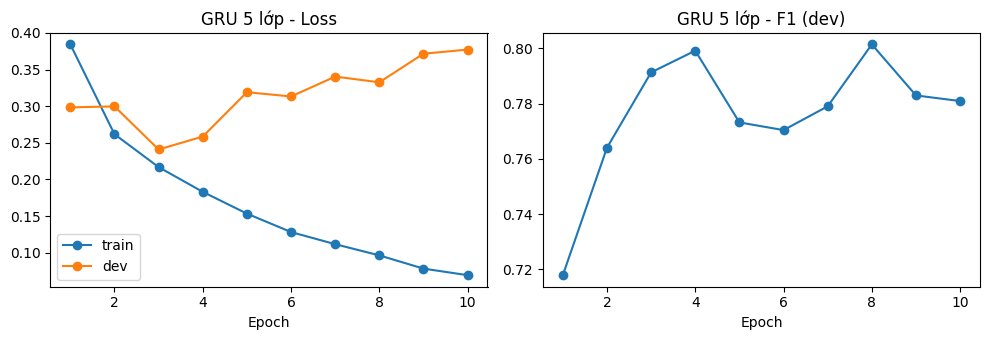

In [14]:
print(classification_report(res_gru["test_true"], res_gru["test_pred"],
                            target_names=LABELS, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(res_gru["test_true"], res_gru["test_pred"],
                                        labels=[0, 1, 2], display_labels=LABELS, colorbar=False)
plt.title("GRU 5 lớp - Confusion matrix (test)")
plt.show()

plot_history(res_gru["history"], "GRU 5 lớp")

- Epoch 8 cho dev macro-F1 cao nhất (0.8014), trên test đạt macro-F1 0.7578 
- F1 của negative là 0.9230 và của positive là 0.9294, còn neutral chỉ 0.4211. Tương tự LSTM
- Dev loss thấp nhất ở epoch 3 rồi tăng dần, train loss vẫn giảm đều, dấu hiệu overfit

### Bài 3: Xây dựng kiến trúc Encoder trong đó Encoder gồm 5 lớp BiLSTM với hidden size là 256 cho bài toán nhận diện thực thể (Name Entity Recognition). Huấn luyện mô hình trên bộ dữ liệu PhoNER và đánh giá độ hiệu quả của mô hình sử dụng độ đo F1.

In [15]:
ner_vocab = build_vocab([row["words"] for row in ner["train"]])
print("Kích thước từ điển NER:", len(ner_vocab))

ner_data = {}
for split in ["train", "dev", "test"]:
    ner_data[split] = []
    for row in ner[split]:
        ids = encode(row["words"], ner_vocab)
        tag_ids = [TAG_TO_ID[tag] for tag in row["tags"]]
        ner_data[split].append((ids, tag_ids))

ner_dev_loader = make_loader(ner_data["dev"], collate_ner, shuffle=False)
ner_test_loader = make_loader(ner_data["test"], collate_ner, shuffle=False)

Kích thước từ điển NER: 2813


In [16]:
class NERBiLSTM(nn.Module):
    # Embedding - BiLSTM - Linear, dự đoán một nhãn cho từng từ

    def __init__(self, vocab_size, num_tags):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, EMB_DIM, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(EMB_DIM, HIDDEN_SIZE, NUM_LAYERS, batch_first=True,
                           bidirectional=True, dropout=DROPOUT)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc = nn.Linear(2 * HIDDEN_SIZE, num_tags)

    def forward(self, ids, lengths):
        emb = self.embedding(ids)
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=ids.size(1))
        return self.fc(self.dropout(out))


def run_ner():
    print("BiLSTM NER 5 lớp")
    seed_all(SEED)
    model = NERBiLSTM(len(ner_vocab), len(TAGS)).to(device)
    params = sum(p.numel() for p in model.parameters())
    print(f"Số tham số: {params:,}")

    train_loader = make_loader(ner_data["train"], collate_ner, shuffle=True)
    history, best_epoch = train_model(model, train_loader, ner_dev_loader, "ner")

    _, test_f1, test_true, test_pred = evaluate(model, ner_test_loader, "ner")
    return {"model": model, "params": params, "history": history, "best_epoch": best_epoch,
            "test_f1": test_f1, "test_true": test_true, "test_pred": test_pred}


In [17]:
res_ner = run_ner()

BiLSTM NER 5 lớp
Số tham số: 8,305,297
Epoch  1 | train loss 0.6932 | dev loss 0.3305 F1 0.6795 | thời gian 6.4s
Epoch  2 | train loss 0.1588 | dev loss 0.1853 F1 0.8336 | thời gian 6.3s
Epoch  3 | train loss 0.0859 | dev loss 0.1507 F1 0.8752 | thời gian 6.3s
Epoch  4 | train loss 0.0627 | dev loss 0.1854 F1 0.8683 | thời gian 6.4s
Epoch  5 | train loss 0.0471 | dev loss 0.1448 F1 0.8895 | thời gian 6.4s
Epoch  6 | train loss 0.0377 | dev loss 0.1487 F1 0.9004 | thời gian 6.3s
Epoch  7 | train loss 0.0266 | dev loss 0.1856 F1 0.8947 | thời gian 6.3s
Epoch  8 | train loss 0.0228 | dev loss 0.1692 F1 0.9010 | thời gian 6.3s
Epoch  9 | train loss 0.0185 | dev loss 0.2019 F1 0.9000 | thời gian 6.3s
Epoch 10 | train loss 0.0153 | dev loss 0.2034 F1 0.9013 | thời gian 6.4s
Epoch tốt nhất theo dev: 10 (F1 dev = 0.9013)


                     precision    recall  f1-score   support

                AGE     0.9687    0.9038    0.9351       582
               DATE     0.9779    0.9637    0.9708      1654
             GENDER     0.9566    0.9069    0.9311       462
                JOB     0.6545    0.4162    0.5088       173
           LOCATION     0.9127    0.8969    0.9047      4441
               NAME     0.8106    0.5786    0.6752       318
       ORGANIZATION     0.8213    0.7691    0.7944       771
         PATIENT_ID     0.9410    0.9631    0.9519      2005
SYMPTOM_AND_DISEASE     0.8083    0.7500    0.7781      1136
     TRANSPORTATION     0.8549    0.8549    0.8549       193

          micro avg     0.9105    0.8793    0.8947     11735
          macro avg     0.8707    0.8003    0.8305     11735
       weighted avg     0.9076    0.8793    0.8923     11735

Số tham số: 8,305,297 | Thời gian trung bình: 6.3 giây/epoch | Epoch tốt nhất: 10


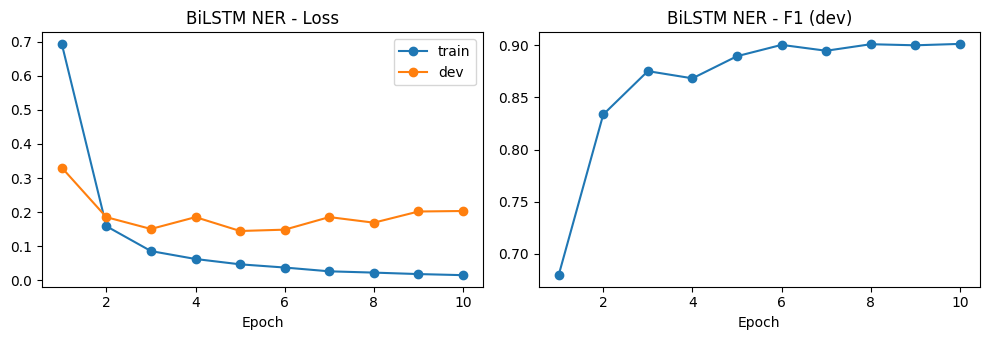

In [18]:
# seqeval ở chế độ strict IOB2: một thực thể chỉ đúng khi đúng cả loại lẫn ranh giới
test_true_tags = ids_to_tags(res_ner["test_true"])
test_pred_tags = ids_to_tags(res_ner["test_pred"])
print(entity_report(test_true_tags, test_pred_tags, mode="strict", scheme=IOB2,
                    digits=4, zero_division=0))

mean_seconds = sum(res_ner["history"]["seconds"]) / len(res_ner["history"]["seconds"])
print(f"Số tham số: {res_ner['params']:,} | Thời gian trung bình: {mean_seconds:.1f} giây/epoch | "
      f"Epoch tốt nhất: {res_ner['best_epoch']}")

plot_history(res_ner["history"], "BiLSTM NER")

- test entity micro-F1 là 0.8947, sát với dev 0.9013. dev F1 gần như đi ngang từ epoch 6, epoch 10 được chọn chỉ nhỉnh hơn rất ít. Dev loss thấp nhất ở epoch 5 rồi đi lên
- Kết quả thấp nhất ở thực thể JOB (F1 0.5088) và NAME (F1 0.6752), cao nhất ở DATE và PATIENT_ID.
- Phần lớn thực thể có precision cao hơn recall. Mô hình bỏ sót thực thể nhiều hơn dự đoán nhầm

### Bài 4*a: so sánh num_layers={1,2,5} của LSTM

In [20]:
res_lstm_1 = run_classification("LSTM", 1)
res_lstm_2 = run_classification("LSTM", 2)

>LSTM 1 lớp
Số tham số: 1,032,663
Epoch  1 | train loss 0.3908 | dev loss 0.3005 F1 0.6656 | thời gian 2.1s
Epoch  2 | train loss 0.2531 | dev loss 0.2746 F1 0.7442 | thời gian 2.1s
Epoch  3 | train loss 0.1991 | dev loss 0.2729 F1 0.7565 | thời gian 2.1s
Epoch  4 | train loss 0.1418 | dev loss 0.2808 F1 0.7730 | thời gian 2.0s
Epoch  5 | train loss 0.1067 | dev loss 0.2976 F1 0.7674 | thời gian 2.0s
Epoch  6 | train loss 0.0711 | dev loss 0.3566 F1 0.7807 | thời gian 2.1s
Epoch  7 | train loss 0.0440 | dev loss 0.3667 F1 0.7674 | thời gian 2.0s
Epoch  8 | train loss 0.0311 | dev loss 0.4142 F1 0.7615 | thời gian 2.1s
Epoch  9 | train loss 0.0222 | dev loss 0.4685 F1 0.7817 | thời gian 2.1s
Epoch 10 | train loss 0.0200 | dev loss 0.5050 F1 0.7758 | thời gian 2.1s
Epoch tốt nhất theo dev: 9 (F1 dev = 0.7817)
>LSTM 2 lớp
Số tham số: 1,558,999
Epoch  1 | train loss 0.3792 | dev loss 0.2838 F1 0.7360 | thời gian 3.0s
Epoch  2 | train loss 0.2438 | dev loss 0.2583 F1 0.7659 | thời gian 3.0s

In [22]:
def make_row(name, res):
    seconds = res["history"]["seconds"]
    return {
        "Mô hình": name,
        "Dev F1 tốt nhất": max(res["history"]["dev_f1"]),
        "Test F1": res["test_f1"],
        "Tham số": res["params"],
        "Giây/epoch": sum(seconds) / len(seconds),
        "Epoch tốt nhất": res["best_epoch"],
    }

print("Bài 1 và Bài 2: LSTM so với GRU (macro-F1)")
table_12 = pd.DataFrame([make_row("LSTM 5 lớp", res_lstm), make_row("GRU 5 lớp", res_gru)])
print(table_12.round(4).to_string(index=False))

print("\nBài 4*: LSTM với số lớp khác nhau (macro-F1)")
table_4 = pd.DataFrame([make_row("LSTM 1 lớp", res_lstm_1),
                        make_row("LSTM 2 lớp", res_lstm_2),
                        make_row("LSTM 5 lớp", res_lstm)])
print(table_4.round(4).to_string(index=False))

Bài 1 và Bài 2: LSTM so với GRU (macro-F1)
   Mô hình  Dev F1 tốt nhất  Test F1  Tham số  Giây/epoch  Epoch tốt nhất
LSTM 5 lớp           0.8036   0.7700  3138007      5.6527               8
 GRU 5 lớp           0.8014   0.7578  2468823      4.9489               8

Bài 4*: LSTM với số lớp khác nhau (macro-F1)
   Mô hình  Dev F1 tốt nhất  Test F1  Tham số  Giây/epoch  Epoch tốt nhất
LSTM 1 lớp           0.7817   0.7538  1032663      2.0727               9
LSTM 2 lớp           0.7902   0.7405  1558999      2.9475               6
LSTM 5 lớp           0.8036   0.7700  3138007      5.6527               8


- Giữa bài 1 và 2, F1 của LSTM và GRU chỉ chênh nhẹ, LSTM hơn ở macro-F1 chỉ nhờ neutral (0.4702 so với 0.4211). GRU ít tham số hơn và nhanh hơn. Kết luận: 2 mô hình tương đương.

Bài 4*: 5 lớp LSTM cho điểm F1 cao hơn 1 và 2 lớp ở cả dev và test, nhưng chênh lệch không quá lớn. Đổi lại tham số và thời gian của 5 lớp đều tăng. Mô hình ít lớp có xu hướng overfit nhanh hơn (dev loss tăng nhanh hơn). Kết luận: điểm số dao động nhỏ, chưa khẳng định 5 lớp tốt hơn.